# Create graphs from the soil and air temperatures of the Ruthe field site

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.dates import DateFormatter, MonthLocator
from matplotlib.lines import Line2D

BASE_DIR = Path.cwd()

Helper functions for the soil temperature graphs

In [10]:
DEPTHS = list(range(10, 60, 10))  # down to the maximum rooting depth
MEASURED_DEPTHS = [10, 20, 30, 40, 50]  # only these depths have measurements, deeper values are simulated

# one hue per data source, darker shades for deeper layers (same shade for the same depth in both hues)
shades = np.linspace(0.45, 1.0, len(DEPTHS))
MEASURED_COLORS = dict(zip(DEPTHS, plt.cm.Blues(shades)))
SIMULATED_COLORS = dict(zip(DEPTHS, plt.cm.Oranges(shades)))


def load_soil_temperature(year):
    """Load the daily soil temperature of the growth period ending in the given year."""
    return pd.read_csv(
        f"{BASE_DIR}/data/data_processed/soil_temperature_{str(year)[2:]}.csv",
        index_col="date",
        parse_dates=True,
    )


def plot_soil_temperature(ax, df_soil):
    """Plot one line per depth, colored by whether the values are measured or simulated (HYDRUS)."""
    for depth in DEPTHS:
        temperature = df_soil[str(depth)]
        if depth in MEASURED_DEPTHS:
            simulated = df_soil[f"source_{depth}"] == "HYDRUS"
        else:
            simulated = pd.Series(True, index=df_soil.index)

        # extend simulated periods by one day on both sides so the line connects to the measured values
        simulated_line = (
            simulated | simulated.shift(1, fill_value=False) | simulated.shift(-1, fill_value=False)
        )
        ax.plot(df_soil.index, temperature.where(simulated_line), color=SIMULATED_COLORS[depth], linewidth=2)
        ax.plot(df_soil.index, temperature.where(~simulated), color=MEASURED_COLORS[depth], linewidth=2)


def soil_temperature_legend_handles(two_columns=True):
    """Legend entries for measured and simulated depths, either side by side (two columns) or stacked."""

    def header(label):
        return Line2D([], [], color="none", label=label)

    measured = [
        Line2D([], [], color=MEASURED_COLORS[depth], linewidth=2, label=f"−{depth} cm")
        for depth in MEASURED_DEPTHS
    ]
    # empty entries so both columns have the same length
    padding = [header(" ") for _ in range(len(DEPTHS) - len(MEASURED_DEPTHS))] if two_columns else []
    simulated = [
        Line2D([], [], color=SIMULATED_COLORS[depth], linewidth=2, label=f"−{depth} cm")
        for depth in DEPTHS
    ]
    return [header("Measured"), *measured, *padding, header("Simulated"), *simulated]

## Growth period November 1994 to August 1995

### Soil temperature

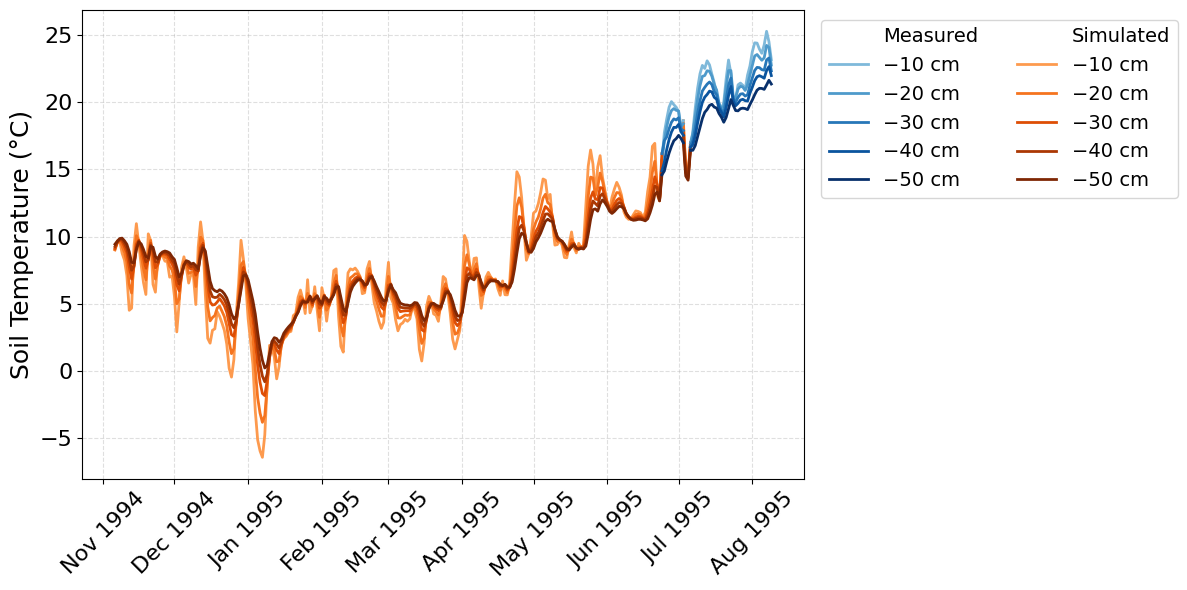

In [11]:
# Soil temperature for 1995 in the depths 10 to 120cm
df_soil = load_soil_temperature(1995)

fig, ax = plt.subplots(figsize=(12, 6))

plot_soil_temperature(ax, df_soil)

ax.grid(True, linestyle="--", alpha=0.4)

ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)

#plt.xlabel("Month", fontsize=18)
plt.ylabel("Soil Temperature (°C)", fontsize=18)
#plt.title("Soil Temperature at Different Depths (Nov 1994 – Aug 1995)", fontsize=20)
plt.legend(handles=soil_temperature_legend_handles(), ncol=2, fontsize=14, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## Growth period November 1995 to August 1996

### Soil temperature

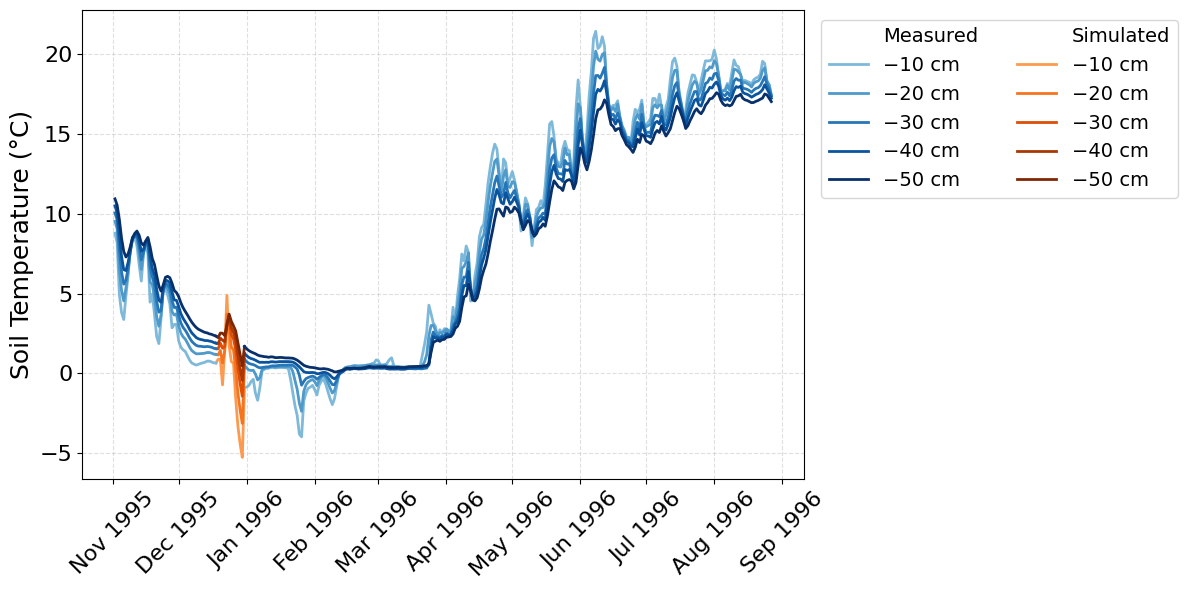

In [4]:
# Soil temperature for 1996 in the depths 10 to 120cm 
df_soil = load_soil_temperature(1996)

fig, ax = plt.subplots(figsize=(12, 6))

plot_soil_temperature(ax, df_soil)

ax.grid(True, linestyle="--", alpha=0.4)

ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)

#plt.xlabel("Month", fontsize=18)
plt.ylabel("Soil Temperature (°C)", fontsize=18)
#plt.title("Soil Temperature at Different Depths (Nov 1995 – Aug 1996)", fontsize=20)
plt.legend(handles=soil_temperature_legend_handles(), ncol=2, fontsize=14, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## Growth period November 1996 to August 1997

### Soil temperature

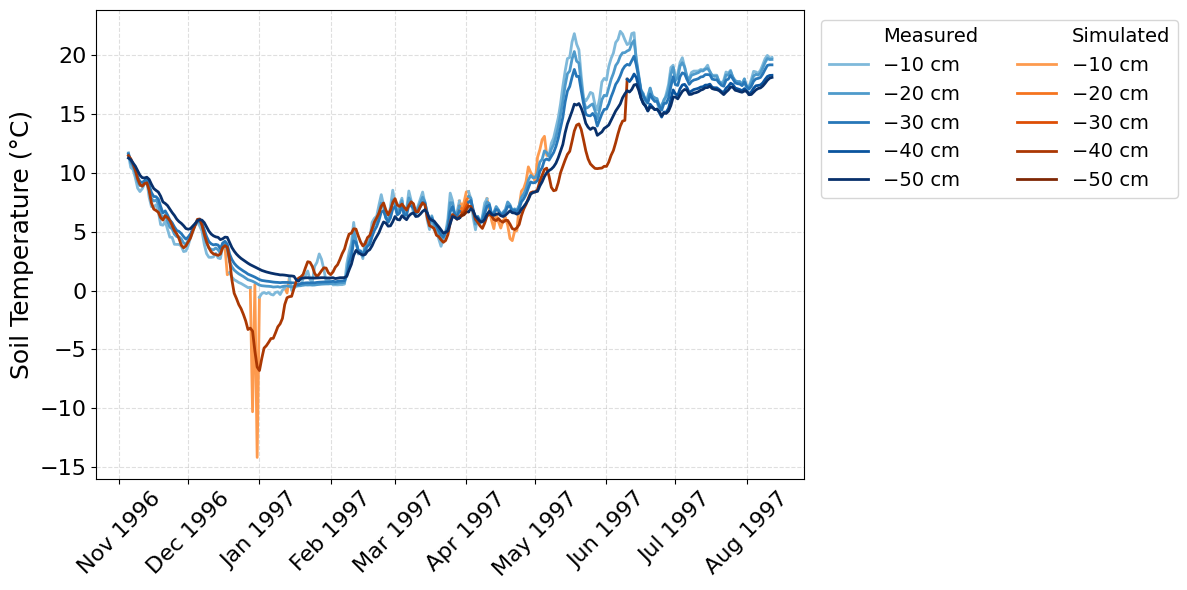

In [5]:
# Soil temperature for 1997 in the depths 10 to 120cm 
df_soil = load_soil_temperature(1997)

fig, ax = plt.subplots(figsize=(12, 6))

plot_soil_temperature(ax, df_soil)

ax.grid(True, linestyle="--", alpha=0.4)

ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)

#plt.xlabel("Month", fontsize=18)
plt.ylabel("Soil Temperature (°C)", fontsize=18)
#plt.title("Soil Temperature at Different Depths (Nov 1996 – Aug 1997)", fontsize=20)
plt.legend(handles=soil_temperature_legend_handles(), ncol=2, fontsize=14, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## All growth periods

Saved /home/jhack/why_fucked/CPlantBox/Ruthe_main_simulation/results/figures/Fig7.png


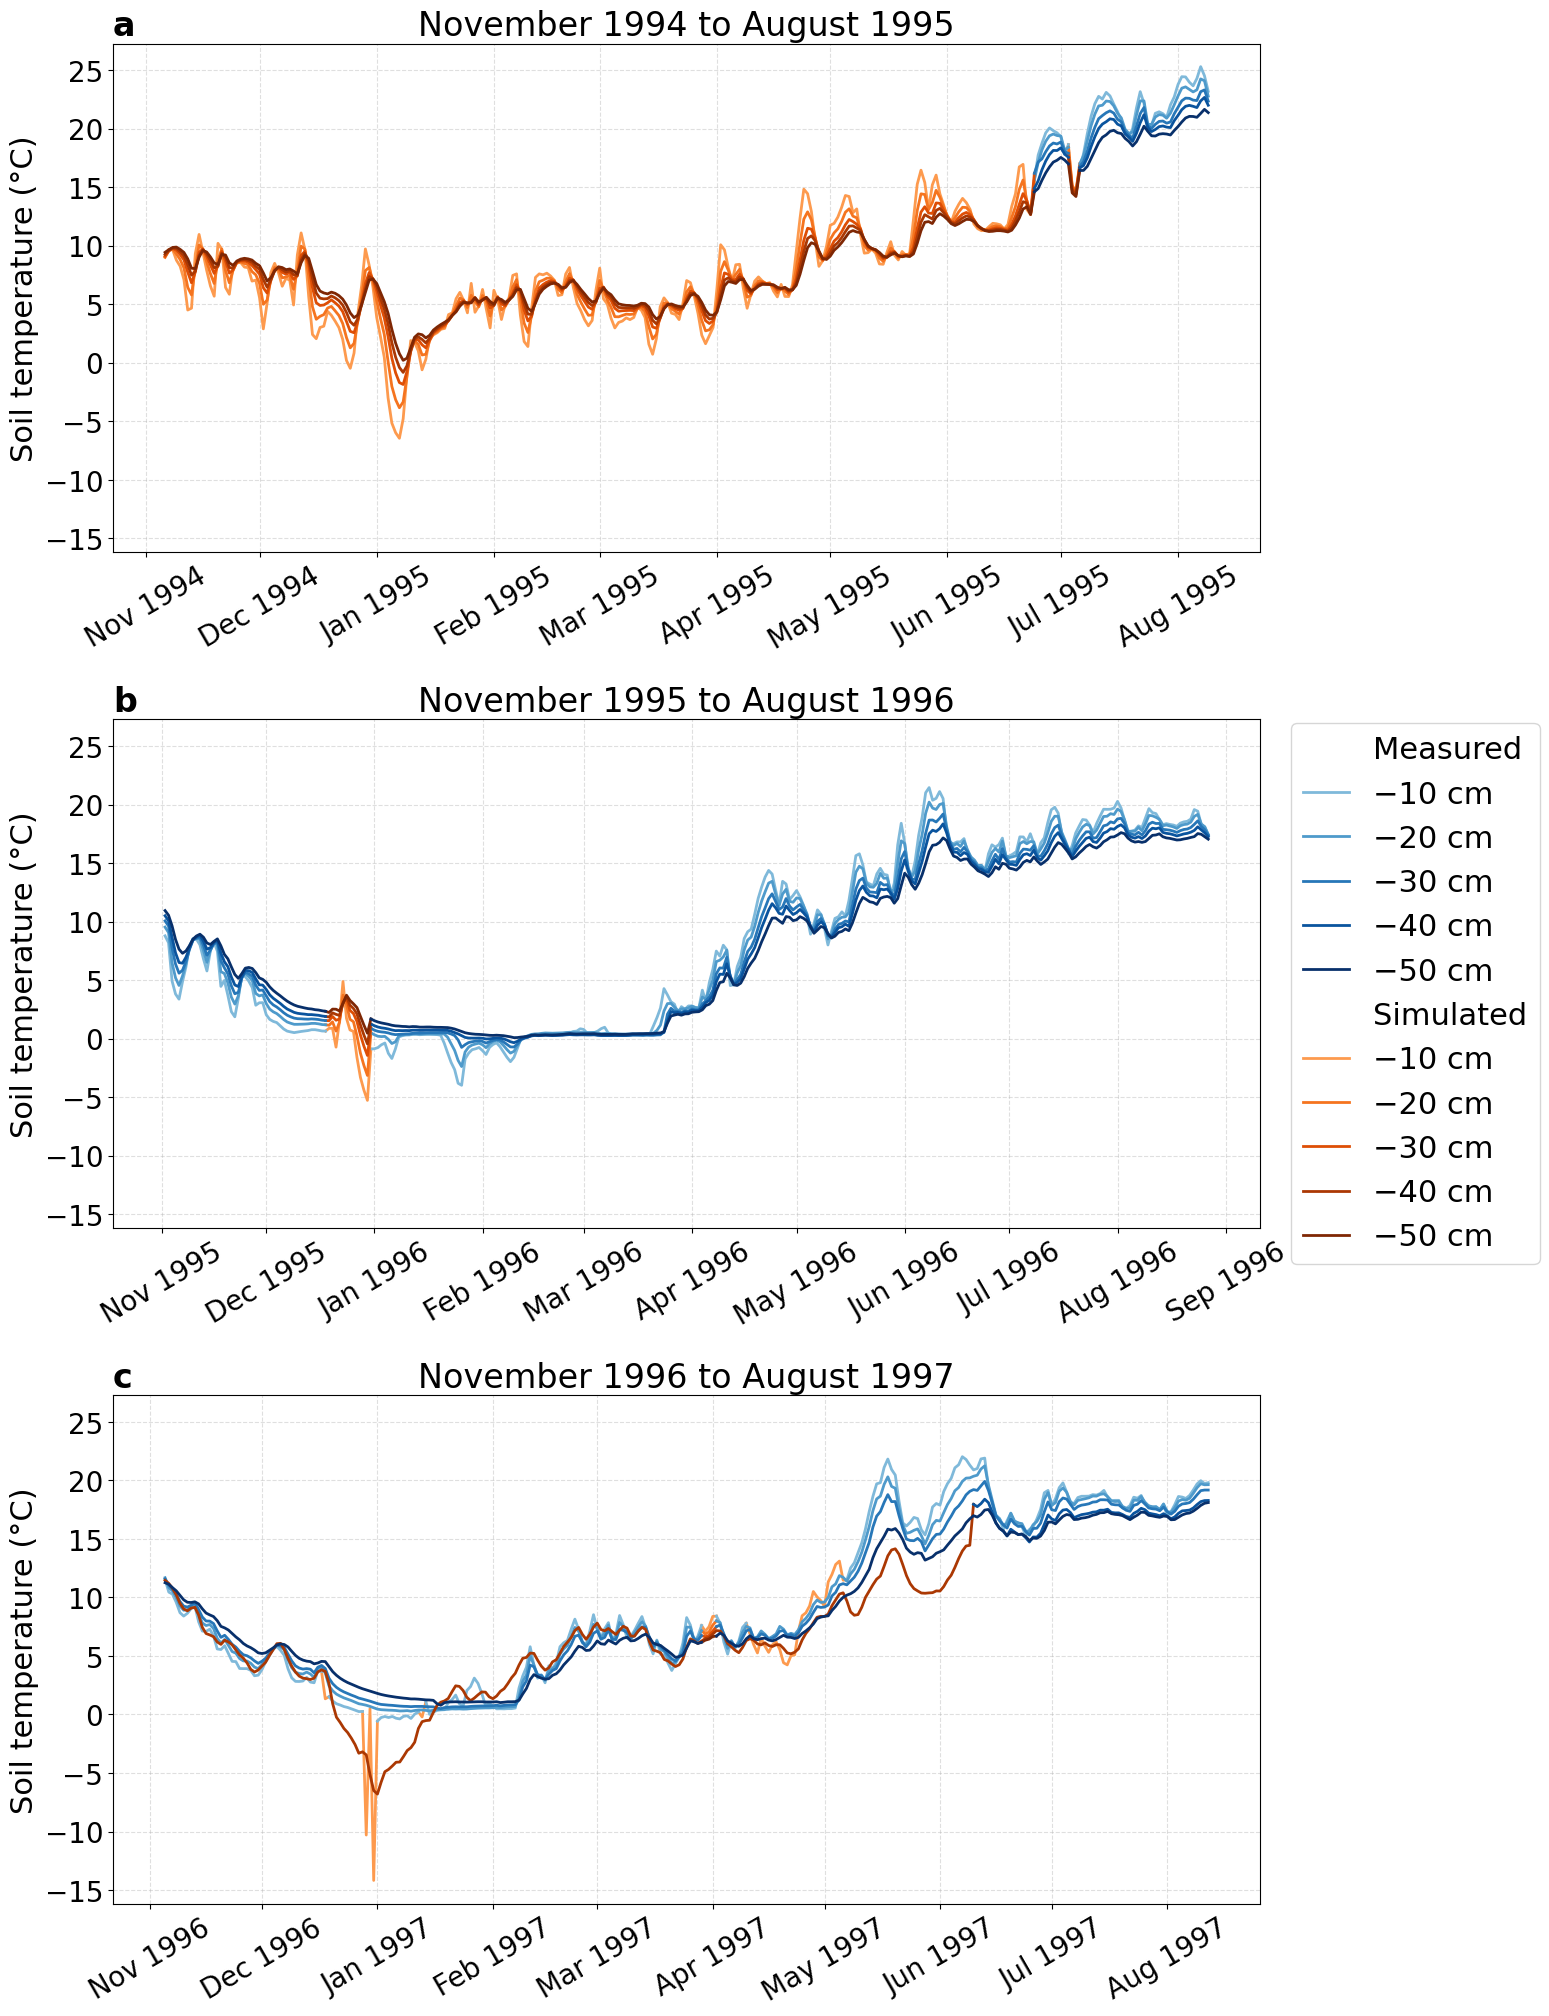

In [6]:
# All three growth periods in one figure with a shared legend
growth_periods = [
    (1995, "November 1994 to August 1995"),
    (1996, "November 1995 to August 1996"),
    (1997, "November 1996 to August 1997"),
]

fig, axes = plt.subplots(3, 1, figsize=(15, 20), sharey=True)

for ax, letter, (year, title) in zip(axes, "abc", growth_periods):
    plot_soil_temperature(ax, load_soil_temperature(year))

    ax.set_title(title, fontsize=24)
    ax.set_title(letter, loc="left", fontweight="bold", fontsize=24)
    ax.set_ylabel("Soil temperature (°C)", fontsize=22)
    ax.grid(True, linestyle="--", alpha=0.4)

    ax.xaxis.set_major_locator(MonthLocator())
    ax.xaxis.set_major_formatter(DateFormatter("%b %Y"))
    ax.tick_params(axis="x", labelrotation=30, labelsize=20)
    ax.tick_params(axis="y", labelsize=20)
    # sharey hides the y tick labels of the lower panels, show them again
    ax.yaxis.set_tick_params(labelleft=True)

fig.legend(
    handles=soil_temperature_legend_handles(two_columns=False),
    fontsize=22,
    handlelength=1.5,
    loc="center left",
    bbox_to_anchor=(0.845, 0.5),
)
fig.subplots_adjust(left=0.07, right=0.835, top=0.975, bottom=0.045, hspace=0.33)

output_path = BASE_DIR / "results" / "figures" / "Fig7.png"
fig.savefig(output_path, dpi=500, bbox_inches='tight')
print(f"Saved {output_path}")
plt.show()

## Comparison graphs of measured vs. simulated

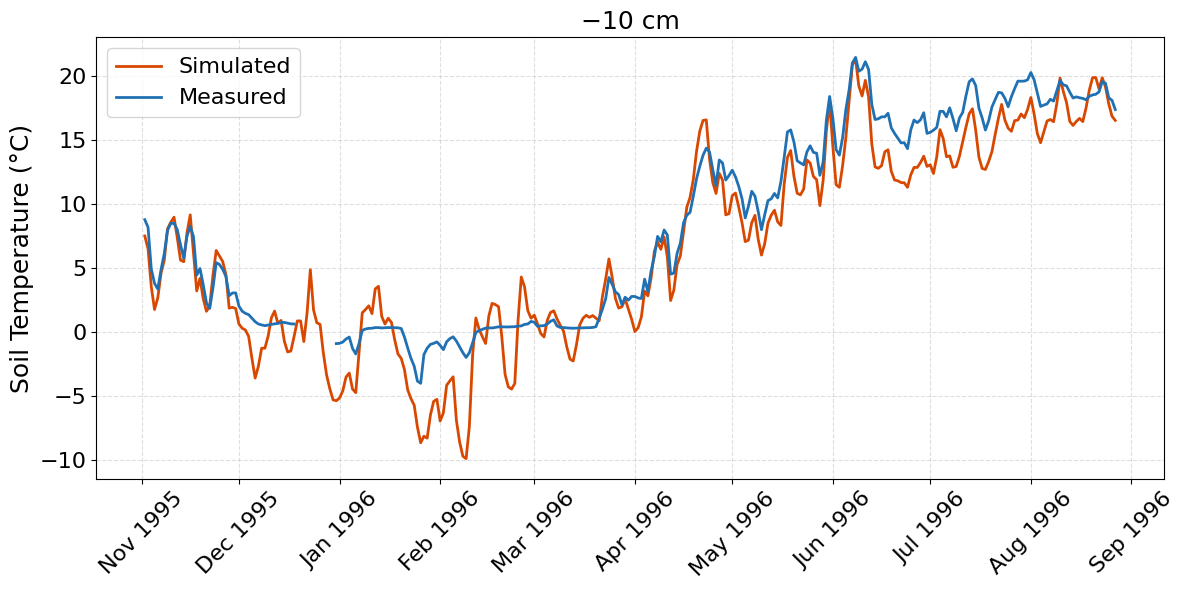

In [12]:
# Measured and simulated (HYDRUS) soil temperature for November 1995 to August 1996
MEASURED_LINE_COLOR = plt.cm.Blues(0.75)
SIMULATED_LINE_COLOR = plt.cm.Oranges(0.75)

df_measured = load_soil_temperature(1996)
df_simulated = pd.read_csv(
    f"{BASE_DIR}/data/data_processed/soil_temperature_sim_only_96.csv",
    index_col="date",
    parse_dates=True,
)


def plot_measured_vs_simulated(ax, depth):
    """Plot the measured values (gaps where none exist) and the simulated values of one depth."""
    measured = df_measured[str(depth)].where(df_measured[f"source_{depth}"] != "HYDRUS")
    ax.plot(df_simulated.index, df_simulated[str(depth)], color=SIMULATED_LINE_COLOR, linewidth=2, label="Simulated")
    ax.plot(measured.index, measured, color=MEASURED_LINE_COLOR, linewidth=2, label="Measured")


fig, ax = plt.subplots(figsize=(12, 6))

plot_measured_vs_simulated(ax, 10)

ax.grid(True, linestyle="--", alpha=0.4)

ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)

plt.ylabel("Soil Temperature (°C)", fontsize=18)
plt.title("−10 cm", fontsize=18)
plt.legend(fontsize=16)
plt.tight_layout()
plt.show()

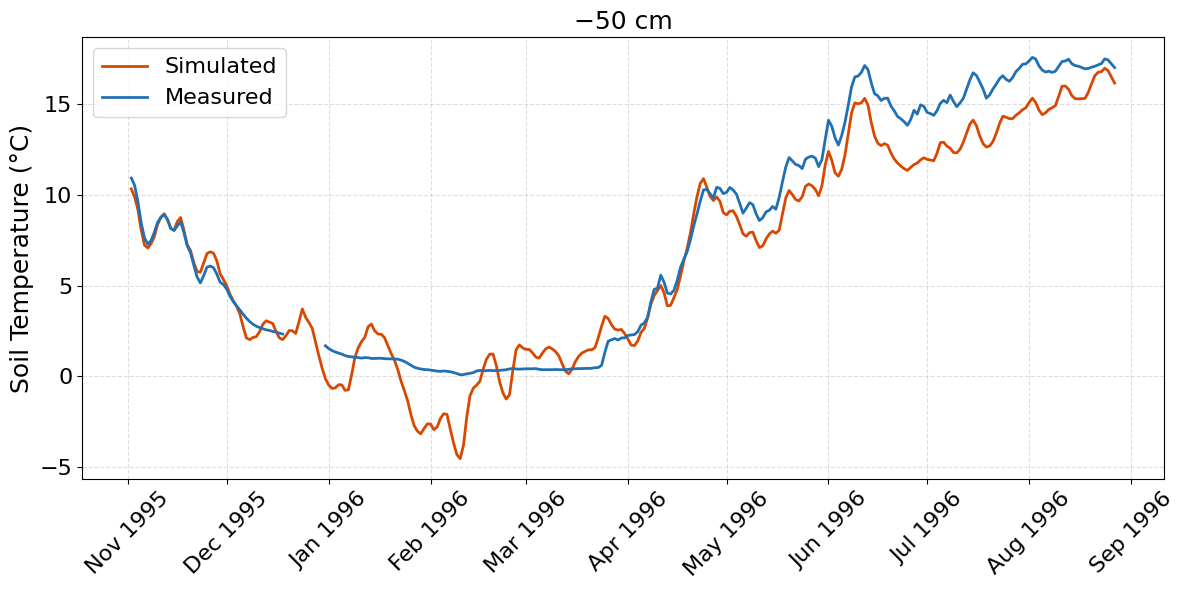

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))

plot_measured_vs_simulated(ax, 50)

ax.grid(True, linestyle="--", alpha=0.4)

ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)

plt.ylabel("Soil Temperature (°C)", fontsize=18)
plt.title("−50 cm", fontsize=18)
plt.legend(fontsize=16)
plt.tight_layout()
plt.show()

Saved /home/jhack/why_fucked/CPlantBox/Ruthe_main_simulation/results/figures/Fig8.png


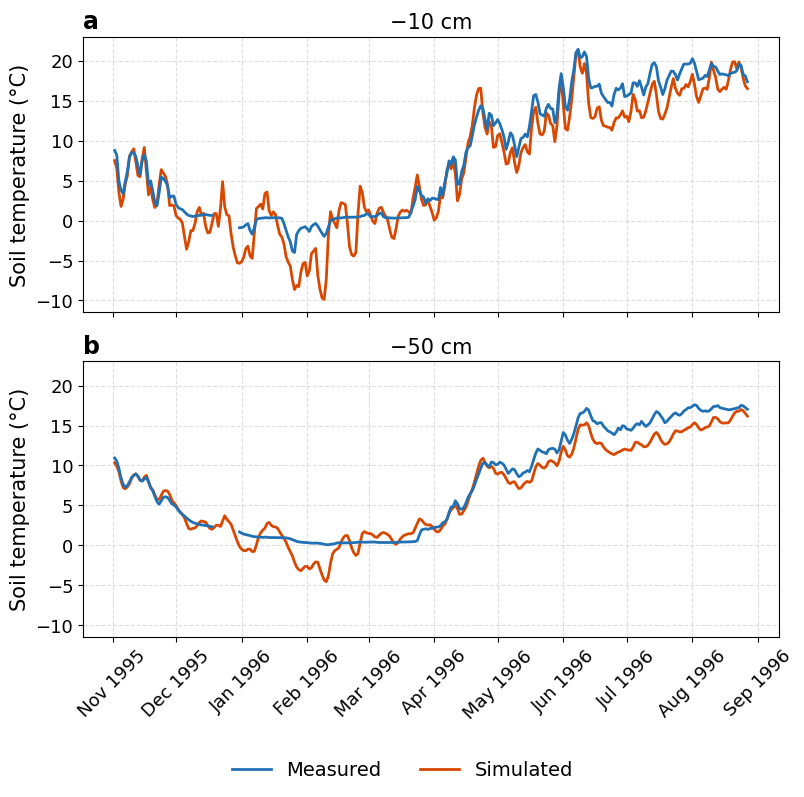

In [14]:
# Both depths in one figure with a shared legend, sized for a full text width in LaTeX
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True, sharey=True)

for ax, letter, depth in zip(axes, "ab", [10, 50]):
    plot_measured_vs_simulated(ax, depth)

    ax.set_title(f"−{depth} cm", fontsize=15)
    ax.set_title(letter, loc="left", fontweight="bold", fontsize=17)
    ax.set_ylabel("Soil temperature (°C)", fontsize=15)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.tick_params(labelsize=13)
    # sharey hides the y tick labels of the lower panel, show them again
    ax.yaxis.set_tick_params(labelleft=True)

axes[-1].xaxis.set_major_locator(MonthLocator())
axes[-1].xaxis.set_major_formatter(DateFormatter("%b %Y"))
axes[-1].tick_params(axis="x", labelrotation=45)

# legend order: measured first
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="lower center", ncol=2, fontsize=14, frameon=False)
fig.subplots_adjust(left=0.11, right=0.98, top=0.95, bottom=0.2, hspace=0.18)

output_path = BASE_DIR / "results" / "figures" / "Fig8.png"
fig.savefig(output_path, dpi=600, bbox_inches='tight')
print(f"Saved {output_path}")
plt.show()

## Temperature response curve for elongation scaling

Saved /home/jhack/why_fucked/CPlantBox/Ruthe_main_simulation/results/figures/Fig2.png


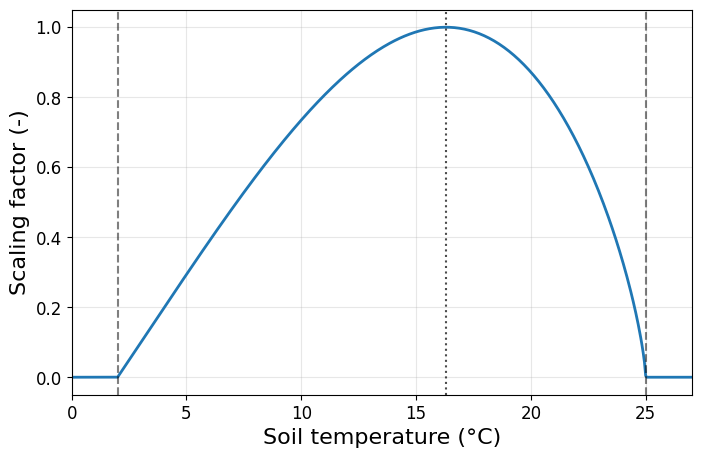

In [8]:
tmin = 2.0
topt = 16.3
tmax = 25.0

temps = np.linspace(tmin - 2.0, tmax + 2.0, 500)
valid = (temps >= tmin) & (temps <= tmax)

if not (tmin < topt < tmax):
    raise ValueError("topt must be strictly between tmin and tmax")

# Same piecewise temperature response as compute_temperature_scaling()
# and Clausnitzer & Hopmans (1994), as used in the paper.
mid = 0.5 * (tmin + tmax)
if topt < mid:
    T = (temps - tmin) / (tmax - tmin)
    Topt = (topt - tmin) / (tmax - tmin)
else:
    T = (temps - tmax) / (tmin - tmax)
    Topt = (topt - tmax) / (tmin - tmax)

sigma = np.log(0.5) / np.log(Topt)  # positive number if Topt in (0,1)

# final scale: sin(pi * T**sigma), with zero response outside the valid domain
scales = np.zeros_like(temps)
scales[valid] = np.sin(np.pi * (T[valid] ** sigma))
scales = np.clip(scales, 0.0, 1.0)

plt.figure(figsize=(8,5))
plt.plot(temps, scales, lw=2)
plt.axvline(tmin, color='k', ls='--', alpha=0.5)
plt.axvline(topt, color='k', ls=':', alpha=0.7)
plt.axvline(tmax, color='k', ls='--', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.xlim(temps.min(), temps.max())
plt.tick_params(labelsize=12)
plt.xlabel("Soil temperature (°C)", fontsize=16)
plt.ylabel("Scaling factor (-)", fontsize=16)
plt.grid(alpha=0.3)

output_path = BASE_DIR / "results" / "figures" / "Fig2.png"
plt.savefig(output_path, dpi=600, bbox_inches='tight')
print(f"Saved {output_path}")
plt.show()